# Cristiano Ronaldo's Goals by Month

This notebook analyzes Cristiano Ronaldo's goalscoring rate by month. The aim of this notebook is to uncover which months he is most prolific in.

In [7]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

CHART_DIR = Path("../../public/images/articles")
CHART_DIR.mkdir(parents=True, exist_ok=True)

MATCHES_DIR = Path("../matches")
match_files = sorted(MATCHES_DIR.glob("*.json"))

print(f"Matches folder: {MATCHES_DIR.resolve()}")
print(f"JSON files found: {len(match_files)}")

if not match_files:
    raise FileNotFoundError(
        "No JSON files found. Make sure the notebook is saved in data/notebooks."
    )

matches = []

for file_path in match_files:
    with file_path.open("r", encoding="utf-8") as file:
        data = json.load(file)

    if isinstance(data, list):
        matches.extend(data)
    elif isinstance(data, dict):
        matches.append(data)

df = pd.DataFrame(matches)

print(f"Match records loaded: {len(df)}")
print("Available columns:", df.columns.tolist())

df.head()

required_columns = ["date", "goals", "minutesPlayed"]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["goals"] = pd.to_numeric(df["goals"], errors="coerce")
df["minutesPlayed"] = pd.to_numeric(
    df["minutesPlayed"], errors="coerce"
)

# Exclude records without a valid date or goal count.
valid_df = df.dropna(subset=["date", "goals"]).copy()

valid_df["month_num"] = valid_df["date"].dt.month
valid_df["month"] = valid_df["date"].dt.month_name()
valid_df["year"] = valid_df["date"].dt.year

# Only use positive, known minutes for rate calculations.
minutes_df = valid_df[
    valid_df["minutesPlayed"].notna()
    & (valid_df["minutesPlayed"] > 0)
].copy()

print(f"All records: {len(df)}")
print(f"Records with valid dates and goals: {len(valid_df)}")
print(f"Records with valid minutes: {len(minutes_df)}")
print(f"Records missing dates: {df['date'].isna().sum()}")
print(f"Records missing goals: {df['goals'].isna().sum()}")
print(f"Records missing minutes: {df['minutesPlayed'].isna().sum()}")

Matches folder: C:\Users\soham\OneDrive\Desktop\ronaldo-archive\ronaldo-archive\data\matches
JSON files found: 25
Match records loaded: 1340
Available columns: ['id', 'date', 'season', 'team', 'competition', 'stage', 'leg', 'opponent', 'venue', 'result', 'scoreFor', 'scoreAgainst', 'minutesPlayed', 'goals', 'assists', 'yellowCard', 'redCard', 'hasMatchComp', 'matchCompUrl', 'hasFullMatch', 'fullMatchUrl', 'stats']
All records: 1340
Records with valid dates and goals: 1340
Records with valid minutes: 1340
Records missing dates: 0
Records missing goals: 0
Records missing minutes: 0


Goals per 90 Minutes

,month,goals,minutes,appearances,goals_per_90
month_num,,,,,
1,January,87,10764,129,0.727
2,February,93,10262,125,0.816
3,March,105,10893,134,0.868
4,April,95,10612,131,0.806
5,May,83,7968,95,0.938
6,June,50,6855,83,0.656
7,July,10,1754,20,0.513
8,August,41,5283,72,0.698
9,September,111,11621,140,0.860


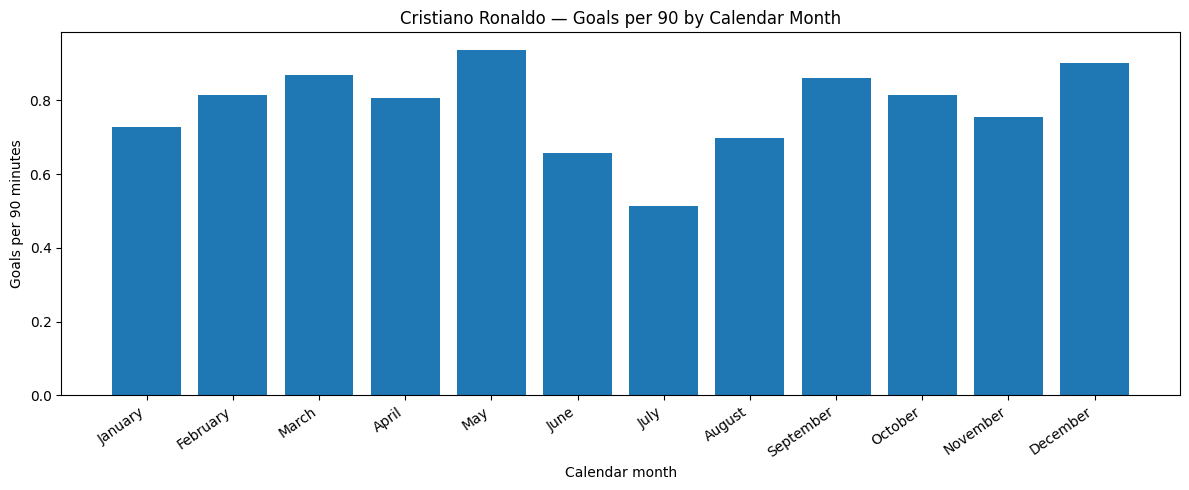

In [8]:
month_order = list(range(1, 13))

monthly_rate = (
    minutes_df.groupby("month_num")
    .agg(
        goals=("goals", "sum"),
        minutes=("minutesPlayed", "sum"),
        appearances=("goals", "size")
    )
    .reindex(month_order, fill_value=0)
)

monthly_rate["month"] = [
    pd.Timestamp(2000, month, 1).strftime("%B")
    for month in month_order
]

monthly_rate["goals_per_90"] = (
    monthly_rate["goals"] / monthly_rate["minutes"] * 90
)

monthly_rate.loc[monthly_rate["minutes"] == 0, "goals_per_90"] = float("nan")

display(
    monthly_rate[
        ["month", "goals", "minutes", "appearances", "goals_per_90"]
    ].round(3)
)

plt.figure(figsize=(12, 5))
plt.bar(monthly_rate["month"], monthly_rate["goals_per_90"])
plt.title("Cristiano Ronaldo — Goals per 90 by Calendar Month")
plt.xlabel("Calendar month")
plt.ylabel("Goals per 90 minutes")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "ronaldo-goals-by-month.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

Goals by Competition

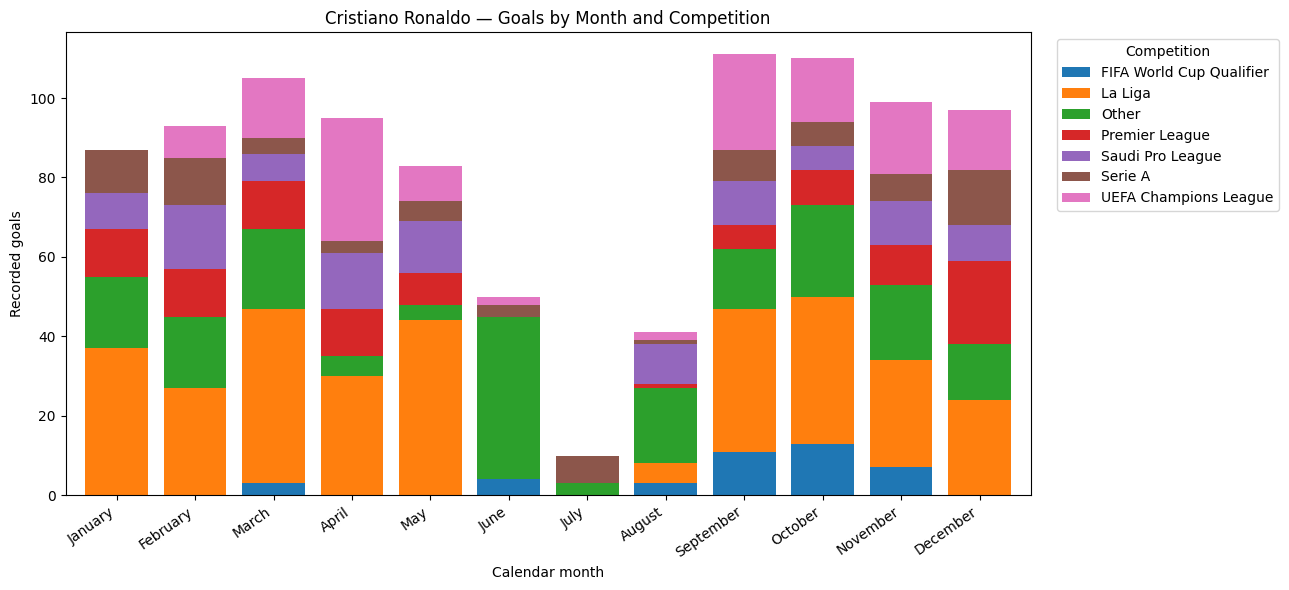

competition_group,FIFA World Cup Qualifier,La Liga,Other,Premier League,Saudi Pro League,Serie A,UEFA Champions League
January,0,37,18,12,9,11,0
February,0,27,18,12,16,12,8
March,3,44,20,12,7,4,15
April,0,30,5,12,14,3,31
May,0,44,4,8,13,5,9
June,4,0,41,0,0,3,2
July,0,0,3,0,0,7,0
August,3,5,19,1,10,1,2
September,11,36,15,6,11,8,24
October,13,37,23,9,6,6,16


In [9]:
if "competition" not in valid_df.columns:
    raise KeyError("The match data does not contain a 'competition' column.")

competition_df = valid_df.copy()

competition_df["competition"] = (
    competition_df["competition"]
    .fillna("Unknown")
    .replace("", "Unknown")
)

# Keep the six competitions with the most recorded goals.
top_competitions = (
    competition_df.groupby("competition")["goals"]
    .sum()
    .nlargest(6)
    .index
)

competition_df["competition_group"] = competition_df["competition"].where(
    competition_df["competition"].isin(top_competitions),
    "Other"
)

competition_monthly = (
    competition_df.groupby(["month_num", "competition_group"])["goals"]
    .sum()
    .unstack(fill_value=0)
    .reindex(month_order, fill_value=0)
)

month_names = [
    pd.Timestamp(2000, month, 1).strftime("%B")
    for month in month_order
]

competition_monthly.index = month_names

competition_monthly.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6),
    width=0.8
)

plt.title("Cristiano Ronaldo — Goals by Month and Competition")
plt.xlabel("Calendar month")
plt.ylabel("Recorded goals")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Competition", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "ronaldo-goals-by-month-competition.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

display(competition_monthly)

Monthly Scoring Variation Across Years

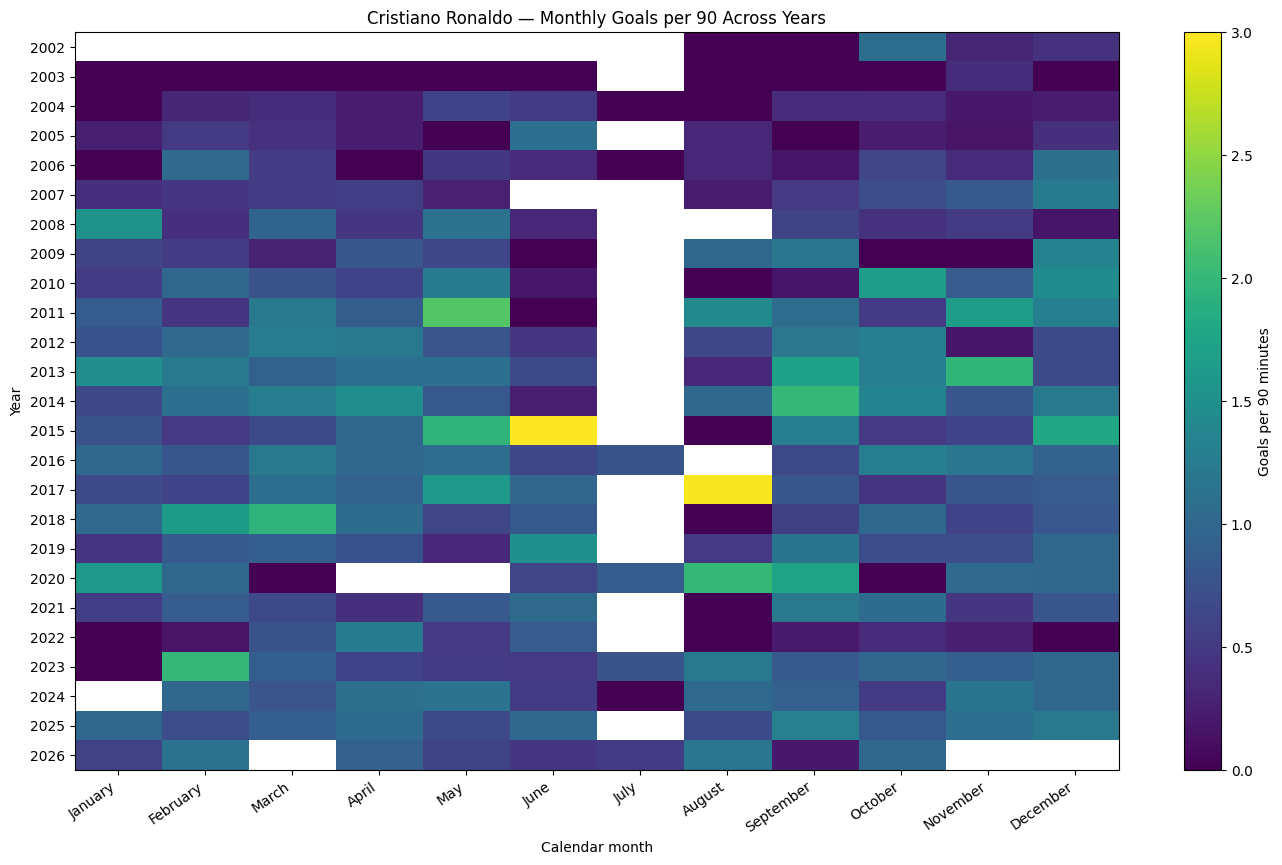

,January,February,March,April,May,June,July,August,September,October,November,December
year,,,,,,,,,,,,
2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,0.000,1.089,0.308,0.425
2003,0.000,0.000,0.000,0.000,0.000,0.000,NaN,0.000,0.000,0.000,0.388,0.000
2004,0.000,0.325,0.393,0.246,0.598,0.507,0.000,0.000,0.385,0.361,0.204,0.244
2005,0.262,0.508,0.431,0.236,0.000,1.091,NaN,0.330,0.000,0.246,0.156,0.420
2006,0.000,1.039,0.517,0.000,0.486,0.354,0.000,0.333,0.174,0.624,0.366,1.107
2007,0.400,0.474,0.534,0.558,0.271,NaN,NaN,0.234,0.504,0.714,0.833,1.243
2008,1.546,0.422,0.964,0.476,1.129,0.333,NaN,NaN,0.612,0.434,0.522,0.175
2009,0.620,0.517,0.299,0.802,0.644,0.000,NaN,1.000,1.173,0.000,0.000,1.343
2010,0.529,1.000,0.769,0.600,1.219,0.189,NaN,0.000,0.167,1.674,0.857,1.458


In [10]:
year_monthly = (
    minutes_df.groupby(["year", "month_num"])
    .agg(
        goals=("goals", "sum"),
        minutes=("minutesPlayed", "sum"),
        appearances=("goals", "size")
    )
    .reset_index()
)

year_monthly["goals_per_90"] = (
    year_monthly["goals"] / year_monthly["minutes"] * 90
)

# Pivot to create one row per year and one column per calendar month.
rate_heatmap = year_monthly.pivot(
    index="year",
    columns="month_num",
    values="goals_per_90"
).reindex(columns=month_order)

rate_heatmap.columns = month_names

plt.figure(figsize=(14, max(5, len(rate_heatmap) * 0.35)))
plt.imshow(rate_heatmap, aspect="auto", interpolation="nearest")
plt.colorbar(label="Goals per 90 minutes")
plt.xticks(range(12), month_names, rotation=35, ha="right")
plt.yticks(range(len(rate_heatmap.index)), rate_heatmap.index)
plt.title("Cristiano Ronaldo — Monthly Goals per 90 Across Years")
plt.xlabel("Calendar month")
plt.ylabel("Year")
plt.tight_layout()
plt.savefig(
    CHART_DIR / "ronaldo-goals-by-month-heatmap.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

display(rate_heatmap.round(3))

Standard Deviation Across Observed Rates

,month,standard_deviation,years_observed,total_goals,total_minutes,total_appearances
month_num,,,,,,
1,January,0.487,23,87,10764,129
2,February,0.452,24,93,10262,125
3,March,0.440,23,105,10893,134
4,April,0.401,23,95,10612,131
5,May,0.551,23,83,7968,95
6,June,0.633,23,50,6855,83
7,July,0.408,7,10,1754,20
8,August,0.760,23,41,5283,72
9,September,0.580,25,111,11621,140


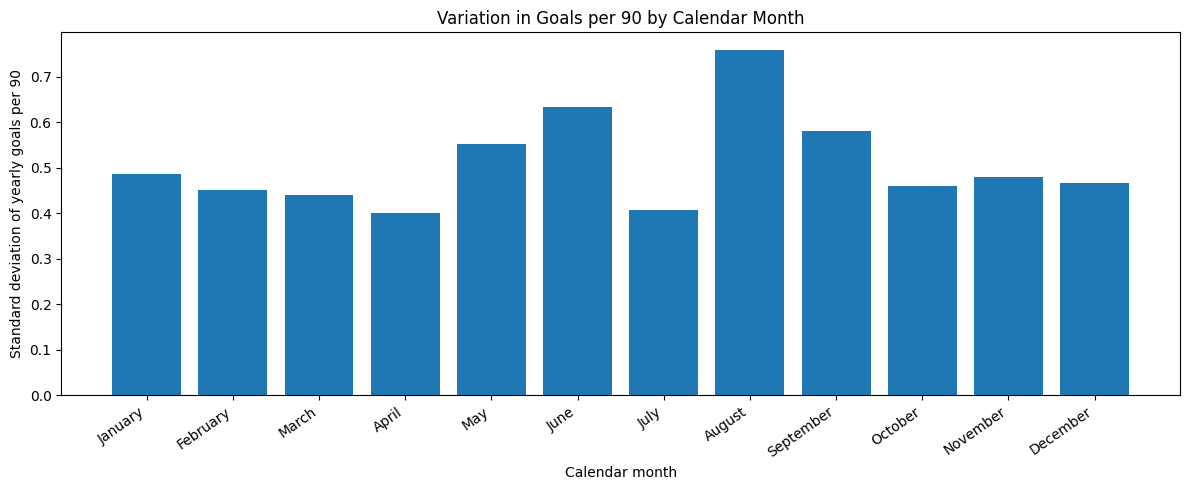

In [11]:
monthly_variation = (
    year_monthly.groupby("month_num")
    .agg(
        standard_deviation=("goals_per_90", "std"),
        years_observed=("goals_per_90", "count"),
        total_goals=("goals", "sum"),
        total_minutes=("minutes", "sum"),
        total_appearances=("appearances", "sum")
    )
    .reindex(month_order)
)

monthly_variation["month"] = month_names

# Months with only one observed yearly rate have no calculable sample SD.
display(
    monthly_variation[
        [
            "month",
            "standard_deviation",
            "years_observed",
            "total_goals",
            "total_minutes",
            "total_appearances"
        ]
    ].round(3)
)

plt.figure(figsize=(12, 5))
plt.bar(
    monthly_variation["month"],
    monthly_variation["standard_deviation"]
)
plt.title("Variation in Goals per 90 by Calendar Month")
plt.xlabel("Calendar month")
plt.ylabel("Standard deviation of yearly goals per 90")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(
    CHART_DIR / "ronaldo-goals-by-month-variation.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()